In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import yaml
import itertools
import more_itertools
from matplotlib.colors import ListedColormap


with open("../plot/plotting_config.yaml") as fp:
    config = yaml.safe_load(fp)

In [2]:
ols_output_folder = "../../../13_gravity_model/output/ols/"

In [3]:
with open("c27.txt", "r") as file:
    c27 = file.read()

colors = {f"{i.split('#')[0]}": f"#{i.split('#')[1]}" for i in c27.split("\n")[:-1]}

#From Color Universal Design (CUD): https://jfly.uni-koeln.de/color/
OkabeIto = ["#E69F00", "#56B4E9", "#009E73", "#F0E442",
            "#0072B2", "#D55E00", "#CC79A7", "#000000"]
OkabeIto = {
    "orange": "#e69f00",
    "skyblue": "#56b4e9",
    "bluishgreen": "#009e73",
    "yellow": "#f0e442",
    "blue": "#0072b2",
    "vermilion": "#d55e00",
    "reddishpurple": "#cc79a7",
    "black": "#000000",
}

In [4]:
colors_to_plot = [OkabeIto[i] for i in ["blue", "skyblue", "reddishpurple", "bluishgreen", "vermilion"]]
okabeito_lc = ListedColormap(list(OkabeIto.values()))

lcolors = [OkabeIto["blue"], OkabeIto["yellow"], OkabeIto["orange"], 
           OkabeIto["skyblue"], OkabeIto["bluishgreen"], OkabeIto["vermilion"]]

In [6]:
def plot_bar(data: pd.DataFrame, colors: list, figsize=(8, 6)):
    fig, ax = plt.subplots(figsize=figsize)
    sns.barplot(
        data=data, x="label", y="coefficient",
        palette=lcolors,
        edgecolor="#2d2d2d",
        ax=ax)

    hatches = itertools.cycle(['//', '\\\\', '-', '|', 'o', 'x', '.'])
    for i, bar in enumerate(ax.patches):
        hatch = next(hatches)
        bar.set_hatch(hatch)

    ax.set_ylabel("OLS coefficients", fontsize=14)
    ax.set_xlabel("Barrier types", fontsize=14)
    ax.tick_params(axis="x", rotation=10)
    ax.axhline(y=0, color="#2d2d2d", linestyle="-", linewidth=0.5)

    ax.errorbar(
    x=data["label"].tolist(),
    y=data["coefficient"].tolist(),
    yerr=[(data["error"]).tolist(), (data["error"]).tolist()],
    fmt=" ",
    color="#2d2d2d",
    elinewidth=2.5,
    zorder=1)

    return fig, ax


In [7]:
def read_gravityjl_output(filename):
    m = pd.read_csv(
        filename,
        skiprows=[0,1,2,3,4,5,6,7],
        skipfooter=1,
        sep="\s+",
        names=["log(mob_ij)", "|", "Estimate", "Std.Error", "t value", "Pr(>|t|)", "Lower 95%", "Upper 95%"],
        engine="python"
        )
    m.drop("|", axis=1, inplace=True)
    m.rename({"log(mob_ij)": "coefficient"}, axis=1, inplace=True)
    return m

read_gravityjl_output(f"{ols_output_folder}/normalized/modelb.txt")

,coefficient,Estimate,Std.Error,t value,Pr(>|t|),Lower 95%,Upper 95%
0,p_i,0.136472,0.000027,5068.8400,0.0,0.136420,0.136525
1,p_j,0.105538,0.000027,3891.4600,0.0,0.105485,0.105591
2,distance_ij,-0.001538,0.000014,-110.4460,0.0,-0.001566,-0.001511
3,primary_count,0.001304,0.000082,15.9807,0.0,0.001144,0.001464
4,secondary_count,-0.020429,0.000109,-187.0880,0.0,-0.020643,-0.020215
5,railway_count,0.011839,0.000078,150.9550,0.0,0.011685,0.011992
6,river_count,-0.001899,0.000099,-19.1154,0.0,-0.002094,-0.001704
7,districts_count,-0.012606,0.000171,-73.8478,0.0,-0.012940,-0.012271
8,neighborhoods_count,0.005703,0.000178,32.0366,0.0,0.005354,0.006052
9,(Intercept),0.000794,0.000007,112.9160,0.0,0.000780,0.000808


In [8]:
label_lookup = {
    "districts": "Districts",
    "neighborhoods": "Neighborhoods",
    "primary": "Primary roads",
    "secondary": "Secondary roads",
    "river": "River",
    "railway": "Railways",
    }

In [9]:
road1 = read_gravityjl_output(f"{ols_output_folder}/not_normalized/model2.txt")
# road1["coefficient"] = road1["coefficient"].apply(lambda x: x[4:-1] if "count" in x else x)
road2 = read_gravityjl_output(f"{ols_output_folder}/not_normalized/model3.txt")
# road2["coefficient"] = road2["coefficient"].apply(lambda x: x[4:-1] if "count" in x else x)
railw = read_gravityjl_output(f"{ols_output_folder}/not_normalized/model4.txt")
# railw["coefficient"] = railw["coefficient"].apply(lambda x: x[4:-1] if "count" in x else x)
river = read_gravityjl_output(f"{ols_output_folder}/not_normalized/model5.txt")
# river["coefficient"] = river["coefficient"].apply(lambda x: x[4:-1] if "count" in x else x)
distr = read_gravityjl_output(f"{ols_output_folder}/not_normalized/model6.txt")
# distr["coefficient"] = distr["coefficient"].apply(lambda x: x[4:-1] if "count" in x else x)
adm10 = read_gravityjl_output(f"{ols_output_folder}/not_normalized/model7.txt")
# adm10["coefficient"] = adm10["coefficient"].apply(lambda x: x[4:-1] if "count" in x else x)
total = read_gravityjl_output(f"{ols_output_folder}/not_normalized/modelb.txt")
# total["coefficient"] = total["coefficient"].apply(lambda x: x[4:-1] if "count" in x else x)


road1n = read_gravityjl_output(f"{ols_output_folder}/normalized/model2.txt")
road2n = read_gravityjl_output(f"{ols_output_folder}/normalized/model3.txt")
railwn = read_gravityjl_output(f"{ols_output_folder}/normalized/model4.txt")
rivern = read_gravityjl_output(f"{ols_output_folder}/normalized/model5.txt")
distrn = read_gravityjl_output(f"{ols_output_folder}/normalized/model6.txt")
adm10n = read_gravityjl_output(f"{ols_output_folder}/normalized/model7.txt")
totaln = read_gravityjl_output(f"{ols_output_folder}/normalized/modelb.txt")

In [10]:
def prepare_data(road1, road2, railw, river, distr, adm10):
    df = pd.DataFrame()
    df = pd.concat([df, road1.query("coefficient == 'primary_count'")])
    df = pd.concat([df, road2.query("coefficient == 'secondary_count'")])
    df = pd.concat([df, railw.query("coefficient == 'railway_count'")])
    df = pd.concat([df, river.query("coefficient == 'river_count'")])
    df = pd.concat([df, distr.query("coefficient == 'districts_count'")])
    df = pd.concat([df, adm10.query("coefficient == 'neighborhoods_count'")])

    df.reset_index(drop=True, inplace=True)
    df = df[["coefficient", "Estimate", "Lower 95%", "Upper 95%"]].copy()
    df.columns = ["label", "coefficient", "lower", "upper"]
    df["error"] = df["coefficient"]-df["lower"]
    df["label"] = df["label"].apply(lambda x: x.split("_count")[0])
    df.set_index("label", inplace=True)
    df = df.reindex(list(label_lookup.keys()))
    df.reset_index(inplace=True)
    df["label"] = df["label"].map(label_lookup)

    return df

data_sep = prepare_data(road1, road2, railw, river, distr, adm10)
data_norm_sep = prepare_data(road1n, road2n, railwn, rivern, distrn, adm10n)

In [11]:
def prepare_total(total):
    df = total.copy()
    df["coefficient"] = df["coefficient"].apply(lambda x: x.split("_count")[0])
    df = df[["coefficient", "Estimate", "Lower 95%", "Upper 95%"]].copy()
    df.columns = ["label", "coefficient", "lower", "upper"]
    df["error"] = df["coefficient"]-df["lower"]
    df.drop([0,1,2,9], inplace=True)
    df.set_index("label", inplace=True)
    df = df.reindex(list(label_lookup.keys()))
    df.reset_index(inplace=True)
    df["label"] = df["label"].map(label_lookup)
    return df

data = prepare_total(total)
data_norm = prepare_total(totaln)

In [12]:
def provide_error_interval():
    return [(v["lower"], v["upper"]) for k, v in result.items()]

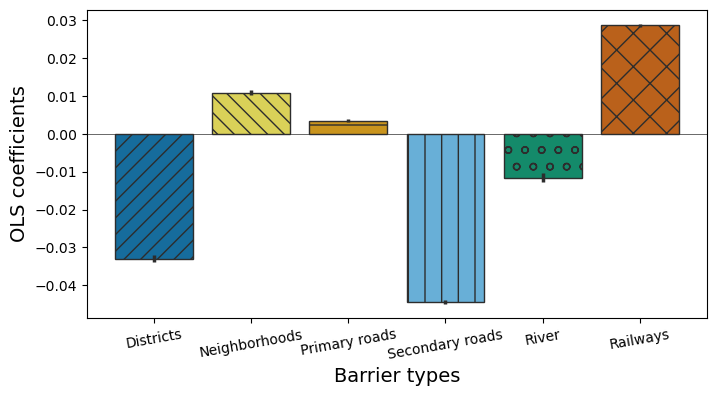

In [13]:
fig, ax = plot_bar(data, colors=lcolors, figsize=(8, 4))
for i in config["formats"]:
    fig.savefig(f"../paper/figures/coefficients_multivariate_bar.{i}",
                dpi=300, facecolor="white", bbox_inches="tight",
                metadata=config["metadata"] if i != "svg" else None)

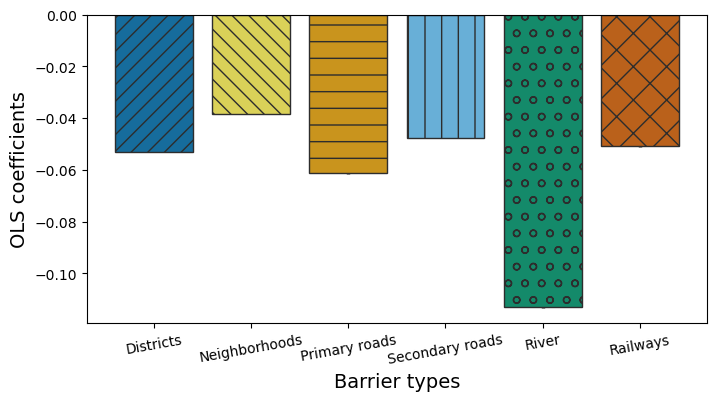

In [14]:
fig_s, ax_s = plot_bar(data_sep, colors=lcolors, figsize=(8, 4))
for i in config["formats"]:
    fig_s.savefig(f"../paper/figures/coefficients_univariate_bar.{i}",
                  dpi=300, facecolor="white", bbox_inches="tight",
                  metadata=config["metadata"] if i != "svg" else None)

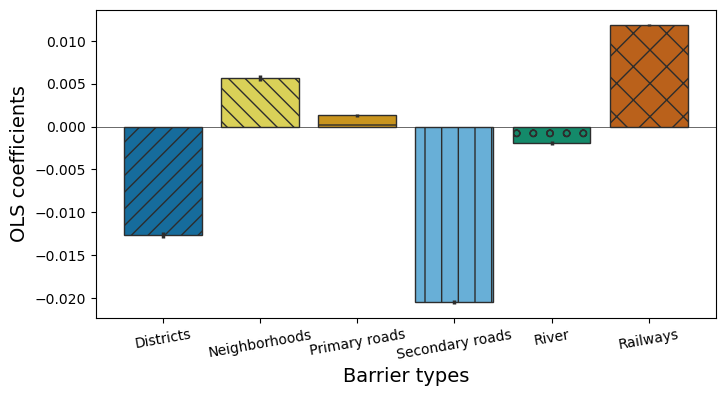

In [15]:
fig_n, ax_n = plot_bar(data_norm, colors=lcolors, figsize=(8, 4))
for i in config["formats"]:
    fig_n.savefig(f"../paper/figures/coefficients_norm_multivariate_bar.{i}",
                  dpi=300, facecolor="white", bbox_inches="tight",
                  metadata=config["metadata"] if i != "svg" else None)

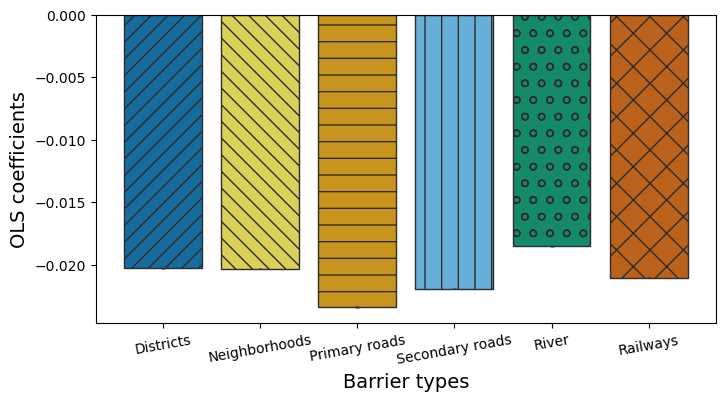

In [16]:
fig_ns, ax_ns = plot_bar(data_norm_sep, colors=lcolors, figsize=(8, 4))
for i in config["formats"]:
    fig_ns.savefig(f"../paper/figures/coefficients_norm_univariate_bar.{i}",
                   dpi=300, facecolor="white", bbox_inches="tight",
                   metadata=config["metadata"] if i != "svg" else None)

In [17]:
md = read_gravityjl_output(f"{ols_output_folder}/not_normalized/modelb.txt")
# md.drop("Pr(>|t|)", axis=1, inplace=True)
md.rename({"coefficient": "variable"}, axis=1, inplace=True)
md["Error"] = md["Estimate"]-md["Lower 95%"]
for c, d in zip(["Estimate", "Std.Error", "t value", "Lower 95%", "Upper 95%", "Error"], [3, 5, 1, 4, 4, 7]):
    md[c] = md[c].apply(lambda x: round(x, d))
md.rename({"t value": "t&nbsp;value"}, axis=1, inplace=True)
print(md[["variable", "Estimate", "Std.Error", "t&nbsp;value", "Error"]].to_markdown())

|    | variable                 |   Estimate |   Std.Error |   t&nbsp;value |     Error |
|---:|:-------------------------|-----------:|------------:|---------------:|----------:|
|  0 | log(p_i)                 |      0.097 |     2e-05   |         5068.8 | 3.76e-05  |
|  1 | log(p_j)                 |      0.076 |     2e-05   |         3891.5 | 3.82e-05  |
|  2 | log(distance_ij)         |     -0.001 |     1e-05   |         -110.4 | 1.01e-05  |
|  3 | log(primary_count)       |      0.003 |     0.00021 |           16   | 0.0004187 |
|  4 | log(secondary_count)     |     -0.044 |     0.00024 |         -187.1 | 0.0004648 |
|  5 | log(railway_count)       |      0.029 |     0.00019 |          151   | 0.0003721 |
|  6 | log(river_count)         |     -0.012 |     0.00061 |          -19.1 | 0.0011898 |
|  7 | log(districts_count)     |     -0.033 |     0.00045 |          -73.8 | 0.0008756 |
|  8 | log(neighborhoods_count) |      0.011 |     0.00034 |           32   | 0.0006588 |
|  9 | (In

In [18]:
print(md[["variable", "Estimate", "Std.Error", "t&nbsp;value", "Error"]].to_latex())

\begin{tabular}{llrrrr}
\toprule
 & variable & Estimate & Std.Error & t&nbsp;value & Error \\
\midrule
0 & log(p_i) & 0.097000 & 0.000020 & 5068.800000 & 0.000038 \\
1 & log(p_j) & 0.076000 & 0.000020 & 3891.500000 & 0.000038 \\
2 & log(distance_ij) & -0.001000 & 0.000010 & -110.400000 & 0.000010 \\
3 & log(primary_count) & 0.003000 & 0.000210 & 16.000000 & 0.000419 \\
4 & log(secondary_count) & -0.044000 & 0.000240 & -187.100000 & 0.000465 \\
5 & log(railway_count) & 0.029000 & 0.000190 & 151.000000 & 0.000372 \\
6 & log(river_count) & -0.012000 & 0.000610 & -19.100000 & 0.001190 \\
7 & log(districts_count) & -0.033000 & 0.000450 & -73.800000 & 0.000876 \\
8 & log(neighborhoods_count) & 0.011000 & 0.000340 & 32.000000 & 0.000659 \\
9 & (Intercept) & 0.001000 & 0.000010 & 116.800000 & 0.000023 \\
\bottomrule
\end{tabular}



In [19]:
def read_full_gravityjl_output(filename):
    p = pd.read_csv(
        filename,
        skiprows=[0,1] + list(range(5, 20)),
        skipfooter=0,
        sep="\s{2,}",
        names=["a", "b", "c", "d"],
        engine="python"
        ).to_numpy().flatten()
    p = dict(list(more_itertools.windowed(p, 2, step=2)))
    m = pd.read_csv(
        filename,
        skiprows=[0,1,2,3,4,5,6,7],
        skipfooter=1,
        sep="\s+",
        names=["log(mob_ij)", "|", "Estimate", "Std.Error", "t value", "Pr(>|t|)", "Lower 95%", "Upper 95%"],
        engine="python"
        )
    m.drop("|", axis=1, inplace=True)
    m.rename({"log(mob_ij)": "coefficient"}, axis=1, inplace=True)
    return p, m

pn, mn = read_full_gravityjl_output(f"{ols_output_folder}/normalized/modelb.txt")
p, m = read_full_gravityjl_output(f"{ols_output_folder}/not_normalized/modelb.txt")

```latex
    \begin{tabularx}{\textwidth}{XrXr}
        \toprule
        Number of Observations: & 148462040 &Degrees of freedom: & 9 \\
        R2: & 0.794 & R2 Adjusted: & 0.794 \\
        F-Stat: & 6.355e7 & p-value: & 0.000 \\
        \bottomrule
    \end{tabularx}
```

In [20]:
def format_table(m, label="tab:ols", caption="OLS", position="ht"):
    return m.to_latex(
        index=False, escape=True,
        label=label, caption=caption, position=position,
        formatters={"Pr(>|t|)": lambda x: round(x, 1), "t value": lambda x: round(x, 4)}
        ).split("\n")


def format_preamble(p) -> str:
    result = r"\begin{tabularx}{\textwidth}{XrXr}" + "\n"
    result += r"\toprule" + "\n"
    for idx, i in enumerate(list(more_itertools.windowed(p.items(), 2, step=2))):
        if idx == 0:
            result += f"{i[0][0]} & {int(i[0][1])} & {i[1][0]} & {int(i[1][1])} \\\\\n"
        else:
            result += f"{i[0][0]} & {i[0][1]:n} & {i[1][0]} & {i[1][1]} \\\\\n"
    result += r"\bottomrule" + "\n"
    result += r"\end{tabularx}"
    return result.split("\n")


def connect_preamble_and_table(p, m):
    # ml = format_table(m)
    return "\n".join(m[:3] + p + m[3:]).replace(r"begin{tabular}", r"begin{tabularx}{\textwidth}")\
        .replace(r"end{tabular}", r"end{tabularx}")


print(connect_preamble_and_table(format_preamble(p), format_table(m)))

\begin{table}[ht]
\caption{OLS}
\label{tab:ols}
\begin{tabularx}{\textwidth}{XrXr}
\toprule
Number of obs: & 148462040 & Degrees of freedom: & 9 \\
R2: & 0.794 & R2 Adjusted: & 0.794 \\
F-Stat: & 6.355e+07 & p-value: & 0.0 \\
\bottomrule
\end{tabularx}
\begin{tabularx}{\textwidth}{lrrrrrr}
\toprule
coefficient & Estimate & Std.Error & t value & Pr(>|t|) & Lower 95\% & Upper 95\% \\
\midrule
log(p\_i) & 0.097107 & 0.000019 & 5068.84 & 0.0 & 0.097069 & 0.097144 \\
log(p\_j) & 0.075758 & 0.000019 & 3891.46 & 0.0 & 0.075720 & 0.075796 \\
log(distance\_ij) & -0.000571 & 0.000005 & -110.446 & 0.0 & -0.000581 & -0.000561 \\
log(primary\_count) & 0.003414 & 0.000214 & 15.9807 & 0.0 & 0.002995 & 0.003833 \\
log(secondary\_count) & -0.044367 & 0.000237 & -187.088 & 0.0 & -0.044832 & -0.043902 \\
log(railway\_count) & 0.028663 & 0.000190 & 150.955 & 0.0 & 0.028291 & 0.029035 \\
log(river\_count) & -0.011603 & 0.000607 & -19.1154 & 0.0 & -0.012793 & -0.010414 \\
log(districts\_count) & -0.032992 &

In [21]:
with open("../paper/ols_table.tex", "w") as fp:
    fp.write(connect_preamble_and_table(format_preamble(p), format_table(m)))

In [ ]:
with open("../paper/ols_table_normalized.tex", "w") as fp:
    fp.write(
        connect_preamble_and_table(
            format_preamble(pn),
            format_table(
                mn,
                label="tab:ols_normalized",
                caption="Normalized OLS")
        )
    )